# 🧪 Project 3: Medical Insurance Data Explorer & ML Baseline

**Objective:**
1. Perform Exploratory Data Analysis (EDA) with 3 insightful visualizations.
2. Train 1 **Regression Model** (predicting medical insurance charges).
3. Train 1 **Classification Model** (predicting whether a patient is a smoker).
4. Export the best model for **Project 4 (FastAPI + Docker ML Service)**.

In [24]:
# Cell 1: Environment Verification
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

print("✅ Setup verified! All core libraries are ready.")
print(f"- Pandas: {pd.__version__}")
print(f"- Scikit-Learn: {sklearn.__version__}")
print(f"- NumPy: {np.__version__}")

✅ Setup verified! All core libraries are ready.
- Pandas: 3.0.6
- Scikit-Learn: 1.9.1
- NumPy: 2.4.6


In [25]:
# Cell 2: Load the Dataset
df = pd.read_csv("data/insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [26]:
# Check data types, row count, and missing values
print("--- INFO ---")
df.info()

print("\n--- MISSING VALUES ---")
print(df.isnull().sum())

--- INFO ---
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB

--- MISSING VALUES ---
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [27]:
# Summary statistics for numerical columns
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


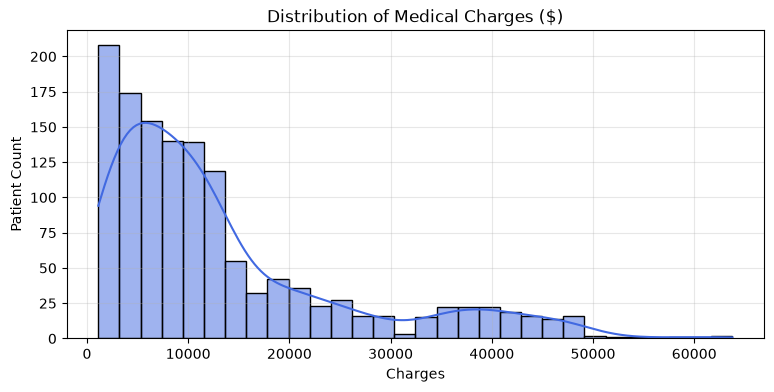

In [28]:
# 1. Distribution of Target Variable (charges)
plt.figure(figsize=(9, 4))
sns.histplot(df["charges"], kde=True, color="royalblue")
plt.title("Distribution of Medical Charges ($)")
plt.xlabel("Charges")
plt.ylabel("Patient Count")
plt.grid(True, alpha=0.3)
plt.show()

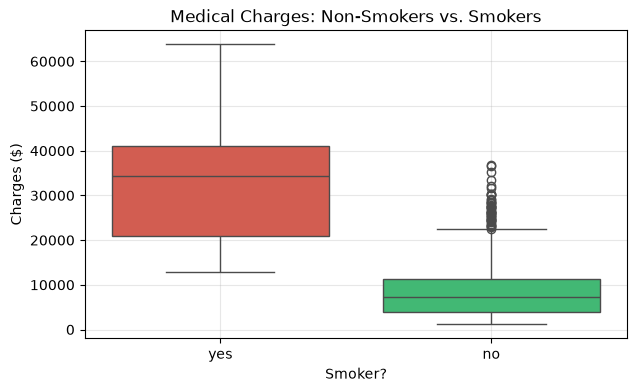

In [29]:
# 2. Charges by Smoker Status
plt.figure(figsize=(7, 4))
sns.boxplot(
    x="smoker",
    y="charges",
    hue="smoker",
    data=df,
    palette={"no": "#2ecc71", "yes": "#e74c3c"},
    legend=False
)
plt.title("Medical Charges: Non-Smokers vs. Smokers")
plt.xlabel("Smoker?")
plt.ylabel("Charges ($)")
plt.grid(True, alpha=0.3)
plt.show()

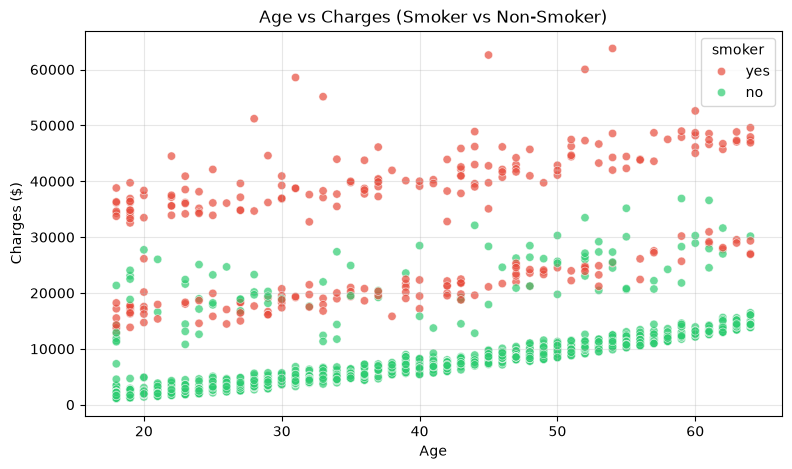

In [30]:
# 3. Age vs. Charges separated by Smoker status
plt.figure(figsize=(9, 5))
sns.scatterplot(x="age", y="charges", hue="smoker", alpha=0.7, data=df, palette={"no": "#2ecc71", "yes": "#e74c3c"})
plt.title("Age vs Charges (Smoker vs Non-Smoker)")
plt.xlabel("Age")
plt.ylabel("Charges ($)")
plt.grid(True, alpha=0.3)
plt.show()

In [31]:
# Convert text columns (sex, smoker, region) into 0s and 1s
df_encoded = pd.get_dummies(df, drop_first=True)

# Separate Features (X) and Target (y)
X = df_encoded.drop("charges", axis=1)  # Everything EXCEPT charges
y = df_encoded["charges"]               # What we want to predict

print("Encoded Columns:", list(X.columns))
print(f"Features shape: {X.shape}, Target shape: {y.shape}")

Encoded Columns: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']
Features shape: (1338, 8), Target shape: (1338,)


In [32]:
from sklearn.model_selection import train_test_split

# Split 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training samples: {len(X_train)}, Testing samples: {len(X_test)}")

Training samples: 1070, Testing samples: 268


In [33]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Initialize & Train
reg_model = LinearRegression()
reg_model.fit(X_train, y_train)

# 2. Predict on test set
y_pred = reg_model.predict(X_test)

# 3. Evaluate
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"📊 Regression Performance:")
print(f"- R² Score: {r2:.3f} (explains {r2*100:.1f}% of variance)")
print(f"- Mean Absolute Error (MAE): ${mae:,.2f}")
print(f"- Root Mean Squared Error (RMSE): ${rmse:,.2f}")

📊 Regression Performance:
- R² Score: 0.784 (explains 78.4% of variance)
- Mean Absolute Error (MAE): $4,181.19
- Root Mean Squared Error (RMSE): $5,796.28


In [34]:
from sklearn.model_selection import train_test_split
x_cls = df_encoded.drop("smoker_yes", axis=1)
y_cls = df_encoded["smoker_yes"]
print(f"Features shape: {x_cls.shape}, Target shape: {y_cls.shape}")

x_cls_train, x_cls_test,y_cls_train, y_cls_test = train_test_split(x_cls, y_cls, test_size=0.2, random_state=42)
print(f"Training samples: {len(x_cls_train)}, Testing samples: {len(x_cls_test)}, Training results: {len(y_cls_train)}, Testing results: {len(y_cls_test)}")

Features shape: (1338, 8), Target shape: (1338,)
Training samples: 1070, Testing samples: 268, Training results: 1070, Testing results: 268


In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

clf_model = LogisticRegression(max_iter=1000)
clf_model.fit(x_cls_train, y_cls_train)

y_pred = clf_model.predict(x_cls_test)

print(f"Accuracy: {accuracy_score(y_cls_test, y_pred):.3f}\n")
print("Confusion Matrix:")
print(confusion_matrix(y_cls_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_cls_test, y_pred))


Accuracy: 0.966

Confusion Matrix:
[[208   6]
 [  3  51]]

Classification Report:
              precision    recall  f1-score   support

       False       0.99      0.97      0.98       214
        True       0.89      0.94      0.92        54

    accuracy                           0.97       268
   macro avg       0.94      0.96      0.95       268
weighted avg       0.97      0.97      0.97       268



In [36]:
import joblib

# Save the trained linear regression model to disk
joblib.dump(reg_model, "insurance_model.joblib")
print("✅ Model successfully exported as 'insurance_model.joblib'!")

✅ Model successfully exported as 'insurance_model.joblib'!


## 📝 Summary of Findings & Model Evaluation

### 1. Dataset & Key Drivers
We analyzed the Medical Cost Personal Dataset containing 1,338 patient records with zero missing values. Through exploratory data analysis, **smoking status** emerged as the single most dominant driver of medical expenses. Non-smokers rarely exceeded \$15,000 in annual charges, whereas smokers consistently ranged from \$15,000 to over \$60,000. Additionally, charges exhibited a strong upward linear trend with **age**, further amplified by high **BMI** (above 30).

### 2. Regression Performance (Predicting Charges)
A baseline `LinearRegression` model was trained on an 80/20 train/test split. The model achieved an **R² score of 0.784**, meaning it accounts for approximately **78.4% of the total variance** in insurance charges. It recorded a **Mean Absolute Error (MAE) of \$4,181.19**, providing a solid baseline for medical expense estimation.

### 3. Classification Performance (Predicting Smoking Status)
A `LogisticRegression` model was trained to predict smoker classification (`smoker_yes`). The classifier achieved **96.6% accuracy** and an **F1-score of 0.92**, successfully identifying 51 out of 54 actual smokers in the test set with an 89% precision and 94% recall.

### 4. Next Step
The regression model has been serialized to `insurance_model.joblib` for deployment as a containerized FastAPI microservice in **Project 4**.